# Practical 10 - Adaptive Median Filter and Otsu

Aim: Denoise using adaptive median filtering, compare PSNR with median filtering, and segment using Otsu thresholding.

Name: Navjot Singh
Roll No: 2025010071


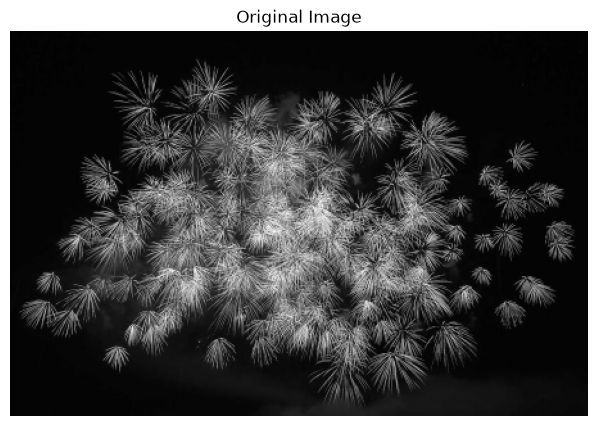

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Name: Navjot Singh")
print("Roll No: 2025010071")

img = cv2.imread("images/navjot_c.jpg", cv2.IMREAD_GRAYSCALE)
img = cv2.resize(img, (450, 300))

smin = 3
smax = 7

plt.figure(figsize=(8, 5))
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()

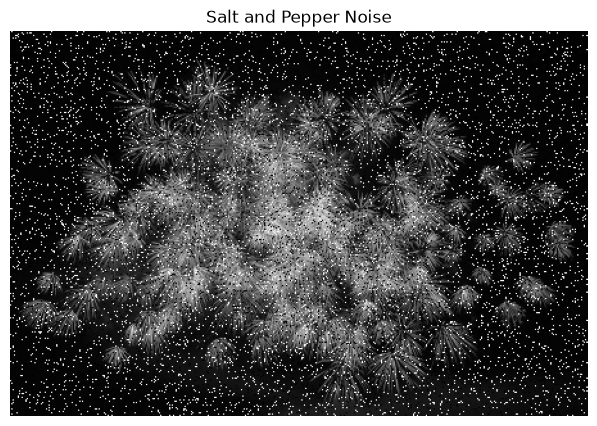

In [2]:
# add salt and pepper noise
noisy = img.copy()
noise = np.random.rand(img.shape[0], img.shape[1])
noisy[noise < 0.05] = 0
noisy[noise > 0.95] = 255

plt.figure(figsize=(8, 5))
plt.imshow(noisy, cmap="gray")
plt.title("Salt and Pepper Noise")
plt.axis("off")
plt.show()

In [3]:
# adaptive median filter
def adaptive_median(image, smin, smax):
    output = image.copy()
    pad = smax // 2
    padded = cv2.copyMakeBorder(image, pad, pad, pad, pad, cv2.BORDER_REFLECT)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            size = smin
            while size <= smax:
                r = size // 2
                window = padded[i + pad - r:i + pad + r + 1, j + pad - r:j + pad + r + 1]
                zmin = np.min(window)
                zmax = np.max(window)
                zmed = np.median(window)
                zxy = padded[i + pad, j + pad]

                if zmin < zmed < zmax:
                    if zmin < zxy < zmax:
                        output[i, j] = zxy
                    else:
                        output[i, j] = zmed
                    break
                size = size + 2
            else:
                output[i, j] = zmed

    return output

Window sizes: 3 to 7
Median filter PSNR: 22.87
Adaptive median filter PSNR: 26.5


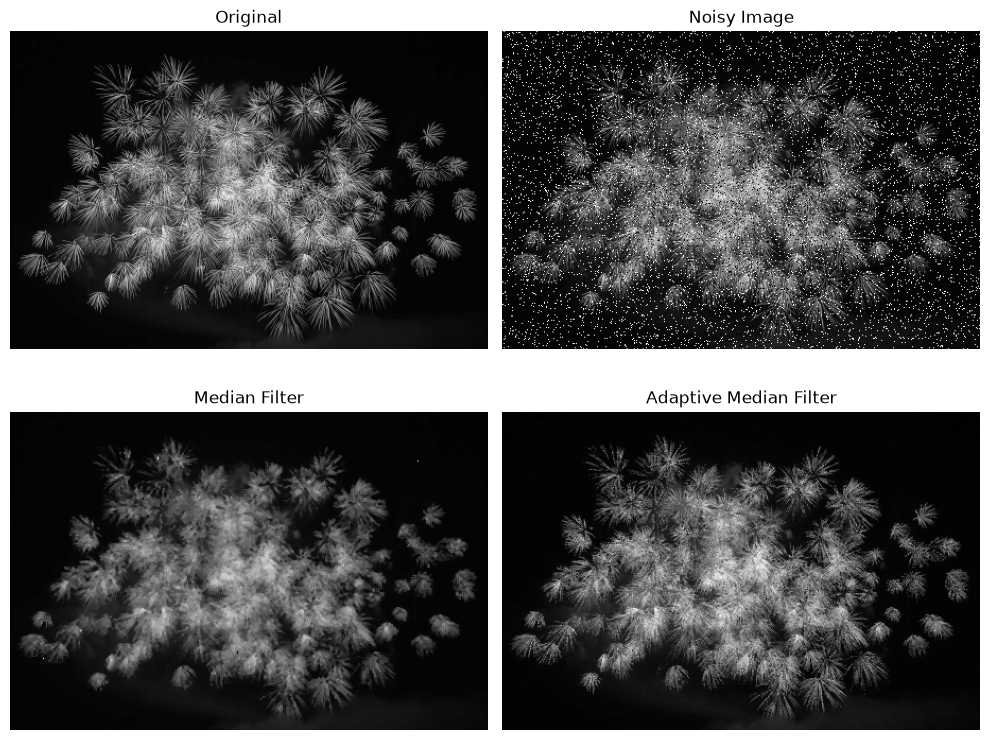

In [4]:
# compare with the normal median filter
median_filter = cv2.medianBlur(noisy, smin)
adaptive_filter = adaptive_median(noisy, smin, smax)

print("Window sizes:", smin, "to", smax)

psnr_median = cv2.PSNR(img, median_filter)
psnr_adaptive = cv2.PSNR(img, adaptive_filter)

print("Median filter PSNR:", round(psnr_median, 2))
print("Adaptive median filter PSNR:", round(psnr_adaptive, 2))

plt.figure(figsize=(10, 8))
plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(noisy, cmap="gray")
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(median_filter, cmap="gray")
plt.title("Median Filter")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(adaptive_filter, cmap="gray")
plt.title("Adaptive Median Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

Otsu threshold: 60.0


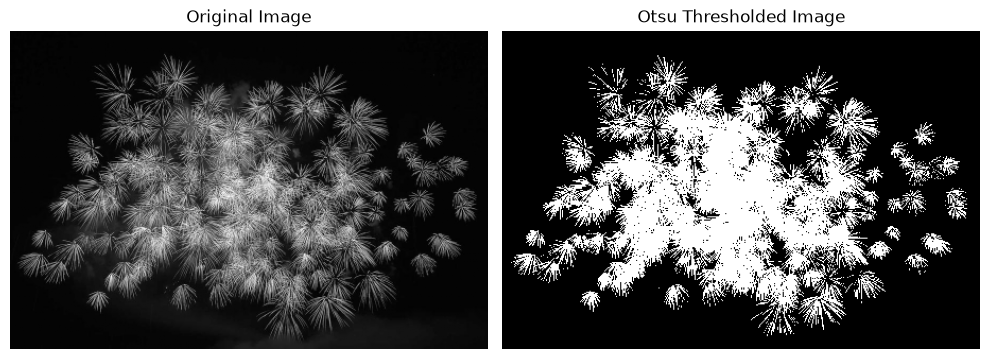

In [5]:
# otsu threshold
threshold, otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Otsu threshold:", threshold)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(otsu, cmap="gray")
plt.title("Otsu Thresholded Image")
plt.axis("off")

plt.tight_layout()
plt.show()